## Experiment 4: Data Wrangling on Real Estate Market

**Aim:** To perform data wrangling on a real estate dataset: clean column names, handle missing values and outliers, and aggregate housing prices by neighborhood and property type.

In [1]:
# A52 Dipanshu Ambilkar
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [2]:
np.random.seed(3)
n = 250
df = pd.DataFrame({
    "Property ID": range(1, n + 1),
    "Neighborhood ": np.random.choice(["Aundh", "Kothrud", "Wakad", "Hinjewadi"], n),
    "Property-Type": np.random.choice(["Flat", "Villa", "Plot"], n),
    "Area (sqft)": np.random.randint(500, 3000, n),
    " Bedrooms": np.random.randint(1, 5, n),
    "Sale Price (Rs)": np.random.randint(3000000, 20000000, n),
    "Year Built": np.random.randint(1990, 2024, n),
})
df.head()

,Property ID,Neighborhood,Property-Type,Area (sqft),Bedrooms,Sale Price (Rs),Year Built
0,1,Wakad,Villa,604,1,10898035,2020
1,2,Aundh,Villa,2153,3,16490355,2003
2,3,Kothrud,Villa,2912,3,16767181,2021
3,4,Hinjewadi,Flat,1239,2,8590920,1991
4,5,Aundh,Flat,2065,3,17276029,2008


In [3]:
df.loc[np.random.choice(n, 12), "Area (sqft)"] = np.nan
df.loc[np.random.choice(n, 4), "Sale Price (Rs)"] = 90000000
print("shape after adding missing values and outliers:", df.shape)

shape after adding missing values and outliers: (250, 7)


In [4]:
df.columns = df.columns.str.strip().str.lower().str.replace(" ", "_").str.replace("(", "").str.replace(")", "").str.replace("-", "_")
print(list(df.columns))

['property_id', 'neighborhood', 'property_type', 'area_sqft', 'bedrooms', 'sale_price_rs', 'year_built']


In [5]:
print("missing values:")
df.isnull().sum()

missing values:


property_id       0
neighborhood      0
property_type     0
area_sqft        12
bedrooms          0
sale_price_rs     0
year_built        0
dtype: int64

In [6]:
df["area_sqft"] = df["area_sqft"].fillna(df["area_sqft"].median())
print("missing area_sqft now:", df["area_sqft"].isnull().sum())

missing area_sqft now: 0


In [7]:
q1 = df["sale_price_rs"].quantile(0.25)
q3 = df["sale_price_rs"].quantile(0.75)
iqr = q3 - q1
df = df[df["sale_price_rs"] <= q3 + 1.5 * iqr]
print("after outlier removal:", df.shape)

after outlier removal: (246, 7)


In [8]:
flats = df[df["property_type"] == "Flat"]
print("flats only:", flats.shape)

flats only: (81, 7)


In [9]:
avg_nb = df.groupby("neighborhood")["sale_price_rs"].mean().sort_values()
print(avg_nb)

neighborhood
Kothrud      1.100382e+07
Aundh        1.147698e+07
Wakad        1.158093e+07
Hinjewadi    1.197643e+07
Name: sale_price_rs, dtype: float64


In [10]:
avg_type = df.groupby("property_type")["sale_price_rs"].mean()
print(avg_type)

property_type
Flat     1.225313e+07
Plot     1.136694e+07
Villa    1.088310e+07
Name: sale_price_rs, dtype: float64


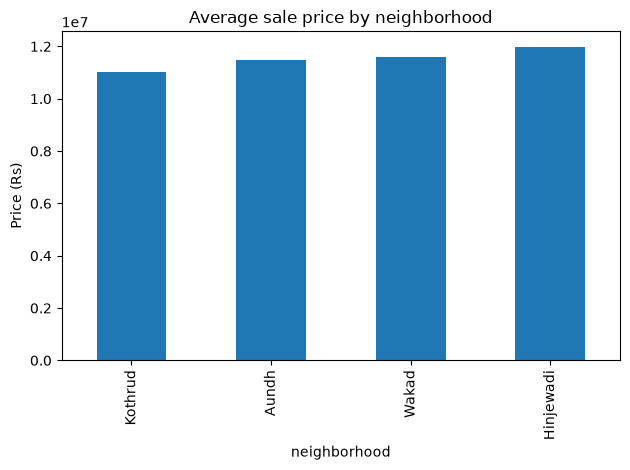

In [11]:
avg_nb.plot(kind="bar")
plt.title("Average sale price by neighborhood")
plt.ylabel("Price (Rs)")
plt.tight_layout()
plt.show()

In [12]:
df = pd.get_dummies(df, columns=["neighborhood", "property_type"], drop_first=True)
print("encoded shape:", df.shape)

encoded shape: (246, 10)


In [13]:
print("done")

done
